# Passaggio 6 sul test: backtest di `finbert_episodio` (17 settembre - 30 ottobre 2026)

**Domanda.** La variante scelta sul train, `finbert_episodio`, migliora la strategia su dati che nessuno aveva guardato? Si confrontano tre versioni: **A** entra a ogni segnale, **B** può bloccare il trade, **C** può anche seguire la notizia (entrare nel verso opposto alla A).

**Regole scritte prima.** Le regole e il modo di giudicare il risultato sono in [docs/Test.md](../docs/Test.md), scritto prima di scaricare i dati del test. Sono le stesse del train, senza cambiamenti: segnale di `03_segnali.ipynb`, decisioni di [varianti_agente/episodio.py](varianti_agente/episodio.py), motore di [backtest.py](backtest.py). 10.000 dollari per gamba, 300.000 di capitale, costo **0** come scenario principale e **5** per confronto.

**Criterio principale:** la differenza in dollari tra B e A, e tra C e A, a costo 0.

**Il test si è fatto una volta sola.** [test_finale.py](test_finale.py) ha calcolato segnali, decisioni e trade il 14 novembre 2026 e li ha salvati in `Results/test/`; non si rifà. Prima di farlo, le stesse funzioni hanno rifatto il train e ritrovato esattamente i suoi 973 segnali e le decisioni e i trade di `finbert_episodio`. Questo notebook legge solo quei file: si può rieseguire senza rifare il test. I controlli di robustezza sono nel [Passaggio 7 sul test](07_test_robustezza.ipynb).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import pandas as pd
import matplotlib.pyplot as plt

from src.config import NEWS_TEST, RESULTS, RESULTS_TEST, TEST_START, TEST_END, read_parquet
from src.backtest import load_trades, add_costs, daily_pnl, summary, by_group, breakeven_cost, entry_window, save_results
from src.signals import list_pairs, load_pair
from src.varianti_agente.confronto import Variante, valuta_blocchi, valuta_segui

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 220
A = load_trades(RESULTS_TEST / "trades_A.csv", allow_test=True)
B = load_trades(RESULTS_TEST / "trades_B.csv", allow_test=True)
C = load_trades(RESULTS_TEST / "trades_C.csv", allow_test=True)
dec = pd.read_csv(RESULTS_TEST / "decisioni.csv", parse_dates=["t_signal", "ep_start"])
d0 = load_pair(list_pairs().pair.iloc[0])
days = pd.DatetimeIndex(d0.ts.normalize().unique())
days = days[(days >= TEST_START) & (days <= TEST_END)]   # giorni di borsa del test, anche quelli senza trade
VERSIONI = {"A": A, "B": B, "C": C}
varianti = [Variante("finbert_episodio", v, "A", True, "FinBERT, finestra dell'episodio", t) for v, t in (("B", B), ("C", C))]
rif = {"A": A}
print(f"{len(A)} segnali in {len(days)} giorni ({days.min():%d/%m} - {days.max():%d/%m}), {len(read_parquet(NEWS_TEST))} notizie; "
      f"{(dec.decision == 'blocca').sum()} blocchi nella B, {(dec.decision_C == 'segui').sum()} segui nella C")

500 segnali in 32 giorni (17/09 - 30/10), 2725 notizie; 7 blocchi nella B, 24 segui nella C


## 1. La versione A sul test

Il riferimento. Guadagno per costo, per coppia, per momento d'ingresso e per motivo di uscita, accanto agli stessi numeri del train.

In [2]:
def per_costo(t, costs=(0, 5)):
    rows = {c: summary(add_costs(t, c), days) for c in costs}
    return pd.DataFrame(rows).T.rename_axis("cost_bps")

A_train = pd.read_csv(RESULTS / "A_per_costo.csv", index_col=0).loc[[0, 5]]
cols = ["trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "pnl_usd", "total_return", "sharpe", "max_drawdown"]
tab = pd.concat({"test": per_costo(A)[cols], "train": A_train[cols]}, names=["periodo", "cost_bps"])
tab.assign(total_return=100 * tab.total_return, max_drawdown=100 * tab.max_drawdown).rename(columns={"total_return": "total_return_pct", "max_drawdown": "max_drawdown_pct"})

trade  gross_bps  net_bps  se_bps  win_rate  profit_factor    pnl_usd  total_return_pct  sharpe  max_drawdown_pct
periodo cost_bps                                                                                                                   
test    0        500.00       4.94     4.94    2.36      0.63           1.31   2,472.42              0.82    4.92             -0.17
        5        500.00       4.94   -15.06    2.36      0.36           0.41  -7,527.58             -2.51  -15.30             -2.65
train   0        973.00       7.44     7.44    2.03      0.60           1.45   7,239.43              2.41    8.13             -0.15
        5        973.00       7.44   -12.56    2.03      0.39           0.52 -12,220.57             -4.07  -13.55             -4.07

In [3]:
print(f"Costo di pareggio sul test: {breakeven_cost(A):.2f} punti base per operazione (train 1,86)")
A_train_pair = pd.read_csv(RESULTS / "A_per_coppia.csv", index_col=0)
pp = by_group(A, "pair", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]]
pp.join(A_train_pair[["trade", "gross_bps"]].add_suffix("_train")).sort_values("gross_bps", ascending=False)

Costo di pareggio sul test: 1.24 punti base per operazione (train 1,86)


,trade,gross_bps,se_bps,win_rate,trade_train,gross_bps_train
pair,,,,,,
ISRG-SYK,26,25.74,16.54,0.73,63,-3.20
CRM-WDAY,30,15.79,14.38,0.63,60,28.19
CL-PG,28,12.75,6.39,0.71,63,6.61
MA-V,43,9.39,2.43,0.70,75,7.54
HD-LOW,38,9.14,4.17,0.68,65,4.39
CSX-UNP,32,7.31,4.62,0.69,61,6.81
DHR-TMO,35,6.20,7.67,0.71,62,6.59
JPM-WFC,41,4.09,4.23,0.61,65,4.31
KO-PEP,33,4.05,6.88,0.61,68,3.53


In [4]:
display(by_group(A, entry_window(A), cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]])
by_group(A, "exit_reason", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]]

,trade,gross_bps,se_bps,win_rate
finestra,,,,
apertura (15-30 min),229,4.86,4.35,0.63
dopo i 30 min,271,5.02,2.35,0.63


,trade,gross_bps,se_bps,win_rate
exit_reason,,,,
fine_giornata,22,-9.12,6.94,0.41
rientro,244,32.96,1.58,0.97
stop,7,-4.02,11.82,0.43
tempo,227,-23.53,4.04,0.30


## 2. Il criterio principale: B e C contro A

Metriche di A, B e C sul test a costo 0 (principale) e 5 (confronto), e la differenza in dollari dalla A (`delta_pnl_usd`). Lo Sharpe è calcolato su 32 giorni e riportato a un anno: è poco affidabile e non va confrontato con quello di un fondo.

In [5]:
rows = []
for c in (0, 5):
    ref = summary(add_costs(A, c), days)
    for v, t in VERSIONI.items():
        s = summary(add_costs(t, c), days)
        rows.append(dict(versione=v, cost_bps=c, trade=s["trade"], net_bps=s["net_bps"], win_rate=s["win_rate"], profit_factor=s["profit_factor"],
                         pnl_usd=s["pnl_usd"], delta_pnl_usd=s["pnl_usd"] - ref["pnl_usd"], sharpe=s["sharpe"], max_drawdown_pct=100 * s["max_drawdown"]))
confronto_test = pd.DataFrame(rows).set_index(["cost_bps", "versione"])
confronto_test

trade  net_bps  win_rate  profit_factor   pnl_usd  delta_pnl_usd  sharpe  max_drawdown_pct
cost_bps versione                                                                                            
0        A           500     4.94      0.63           1.31  2,472.42           0.00    4.92             -0.17
         B           493     4.63      0.63           1.29  2,283.56        -188.86    4.73             -0.19
         C           495     2.48      0.61           1.15  1,229.96      -1,242.46    2.77             -0.21
5        A           500   -15.06      0.36           0.41 -7,527.58           0.00  -15.30             -2.65
         B           493   -15.37      0.35           0.40 -7,576.44         -48.86  -15.91             -2.65
         C           495   -17.52      0.34           0.35 -8,670.04      -1,142.46  -19.85             -3.00

**Regola per i casi a zero** (scritta prima): se l'agente non blocca nessun trade, la B coincide con la A e il test non dice nulla sui blocchi; lo stesso per la C se non segue nessuna notizia.

In [6]:
n_blocchi, n_segui = int((dec.decision == "blocca").sum()), int((dec.decision_C == "segui").sum())
n_invertiti = int((C.c_kind == "segui").sum())
print(f"B: {n_blocchi} trade bloccati su {len(A)}" + (" -> la B coincide con la A: il test non dice nulla sui blocchi" if n_blocchi == 0 else ""))
print(f"C: {n_segui} segui, di cui {n_invertiti} nel verso opposto alla A e {n_segui - n_invertiti} nello stesso verso (restano il trade della A)"
      + (" -> la C coincide con la B: il test non dice nulla sul seguire" if n_invertiti == 0 else ""))

B: 7 trade bloccati su 500
C: 24 segui, di cui 21 nel verso opposto alla A e 3 nello stesso verso (restano il trade della A)


## 3. L'agente sceglie bene?

Gli stessi controlli del train (Passaggio 6, sezione 4), accanto ai valori del train.

- **B**: i trade bloccati rientrano meno dei tenuti (`p_fisher`, test esatto di Fisher)? Sono peggiori di 5.000 blocchi a caso dello stesso numero (`p_caso`: sotto 0,05 l'agente toglie trade peggiori del caso, vicino a 1 toglie proprio i migliori)?
- **C**: quando l'agente entra nel verso opposto alla A, la notizia aveva ragione? `notizia_giusta` è la quota di quei trade in guadagno.

In [7]:
blocchi = pd.concat({"test": valuta_blocchi(varianti, rif).loc[["finbert_episodio"]],
                     "train": pd.read_csv(RESULTS / "bloccati_contro_caso.csv", index_col=0).loc[["finbert_episodio"]]}, names=["periodo"])
blocchi

,,riferimento,bloccati,rientro_bloccati,rientro_tenuti,p_fisher,lordo_medio_bloccati,lordo_mediano_bloccati,lordo_medio_tenuti,p_caso
periodo,variante,,,,,,,,,
test,finbert_episodio,A,7,0.43,0.49,1.00,26.98,37.48,4.63,0.90
train,finbert_episodio,A,5,0.00,0.48,0.06,56.98,-8.97,7.18,0.97


In [8]:
segui = pd.concat({"test": valuta_segui(varianti, rif).loc[["finbert_episodio"]],
                   "train": pd.read_csv(RESULTS / "notizia_giusta_C.csv", index_col=0).loc[["finbert_episodio"]]}, names=["periodo"])
segui

,,riferimento,segui,notizia_giusta,lordo_medio_C,lordo_mediano_C,lordo_medio_rif_stessi
periodo,variante,,,,,,
test,finbert_episodio,A,21,0.24,-25.05,-23.09,25.05
train,finbert_episodio,A,20,0.55,-8.92,5.82,8.92


**I trade bloccati, uno per uno**, con le notizie mirate che l'agente ha letto nell'episodio e il risultato che avrebbero avuto nella A.

In [9]:
pd.options.display.max_colwidth = 160
blk = dec[dec.decision == "blocca"].merge(A[["signal_id", "exit_reason", "gross_bps"]], on="signal_id")
blk[["signal_id", "pair", "t_signal", "ep_kind", "n_strong", "exit_reason", "gross_bps", "headlines"]]

,signal_id,pair,t_signal,ep_kind,n_strong,exit_reason,gross_bps,headlines
0,80,ISRG-SYK,2026-09-25 09:45:00,dalla notte,1,rientro,37.48,"Here's How Much $1000 Invested In Intuitive Surgical 10 Years Ago Would Be Worth Today | Bronstein, Gewirtz & Grossman, LLC Investigates Potential Claims Ag..."
1,111,ISRG-SYK,2026-09-29 09:45:00,dalla notte,1,tempo,54.09,Pomerantz LLP Announces Investigation into Stryker Corporation
2,127,DHR-TMO,2026-09-29 15:09:00,in seduta,1,fine_giornata,25.25,Leica Biosystems Completes Acquisition of StatLab Medical Products
3,193,BAC-C,2026-10-06 09:45:00,in seduta,1,rientro,63.13,Capitolis Secures $220 Million in Financing with Participation from Citi | Bank of America Launches Expanded Fraud-Awareness Initiative for Small Businesses
4,353,CRM-WDAY,2026-10-20 09:50:00,dalla notte,1,tempo,-95.21,Salesforce Launches Slack Frontline Add-on for Enterprise+ Customers | Salesforce To Acquire Braze For ~$5.66B | Salesforce Bets $5.7 Billion on AI Marketin...
5,418,ISRG-SYK,2026-10-26 09:45:00,in seduta,1,tempo,10.48,Stryker Completes Acquisition of ZuriMED
6,487,CRM-WDAY,2026-10-30 09:45:00,dalla notte,1,rientro,93.65,Salesforce to Acquire Defense Tech Firm Rune Technologies


**I trade seguiti nel verso opposto alla A**: guadagno della C e guadagno che avrebbe avuto la A sullo stesso segnale.

In [10]:
f = C[C.c_kind == "segui"].merge(A[["signal_id", "gross_bps"]], on="signal_id", suffixes=("_C", "_A"))
f = f.merge(dec[["signal_id", "ep_kind", "rel_score"]], on="signal_id")
f[["signal_id", "pair", "t_signal", "ep_kind", "rel_score", "direction", "exit_reason", "gross_bps_C", "gross_bps_A"]]

,signal_id,pair,t_signal,ep_kind,rel_score,direction,exit_reason,gross_bps_C,gross_bps_A
0,15,KO-PEP,2026-09-18 09:45:00,dalla notte,0.86,long KO / short PEP,tempo,-15.67,15.67
1,16,PYPL-XYZ,2026-09-18 09:45:00,dalla notte,-0.93,short PYPL / long XYZ,rientro,-48.31,48.31
2,13,GS-MS,2026-09-18 09:45:00,dalla notte,-1.03,short GS / long MS,tempo,34.56,-34.56
3,12,DHR-TMO,2026-09-18 09:45:00,dalla notte,-0.74,short DHR / long TMO,tempo,-36.07,36.07
4,26,JPM-WFC,2026-09-21 09:45:00,dalla notte,1.28,long JPM / short WFC,tempo,-31.64,31.64
5,28,MA-V,2026-09-21 09:46:00,dalla notte,0.61,long MA / short V,rientro,-10.33,10.33
6,48,CRM-WDAY,2026-09-23 09:45:00,dalla notte,0.88,long CRM / short WDAY,rientro,-129.97,129.97
7,51,PYPL-XYZ,2026-09-23 09:45:00,dalla notte,0.79,long PYPL / short XYZ,tempo,-21.97,21.97
8,194,COP-EOG,2026-10-06 09:45:00,dalla notte,0.91,long COP / short EOG,tempo,21.03,-21.03
9,219,JPM-WFC,2026-10-07 11:04:00,in seduta,0.86,long JPM / short WFC,tempo,45.13,-45.13


## 4. Coerenza con il train

La differenza dalla A, a costo 0, ha lo stesso segno che sul train? Le differenze sono anche espresse per giorno di borsa, perché il test ha la metà dei giorni del train.

In [11]:
train_cmp = pd.read_csv(RESULTS / "confronto_versioni.csv").query("variante == 'finbert_episodio'").set_index(["cost_bps", "versione"])
coer = pd.DataFrame({
    "delta_train_usd": train_cmp.delta_pnl_usd,
    "delta_test_usd": confronto_test.query("versione != 'A'").delta_pnl_usd,
})
coer["delta_train_per_giorno"] = coer.delta_train_usd / 64
coer["delta_test_per_giorno"] = coer.delta_test_usd / len(days)
coer["stesso_segno"] = (coer.delta_train_usd > 0) == (coer.delta_test_usd > 0)
coer

delta_train_usd  delta_test_usd  delta_train_per_giorno  delta_test_per_giorno  stesso_segno
cost_bps versione                                                                                              
0        B                 -284.92         -188.86                   -4.45                  -5.90          True
         C                 -650.77       -1,242.46                  -10.17                 -38.83          True
5        B                 -184.92          -48.86                   -2.89                  -1.53          True
         C                 -570.77       -1,142.46                   -8.92                 -35.70          True

## 5. Curve di capitale (costo 0)

Rendimento cumulato sul capitale di 300.000 dollari, giorno per giorno, per A, B e C sul test.

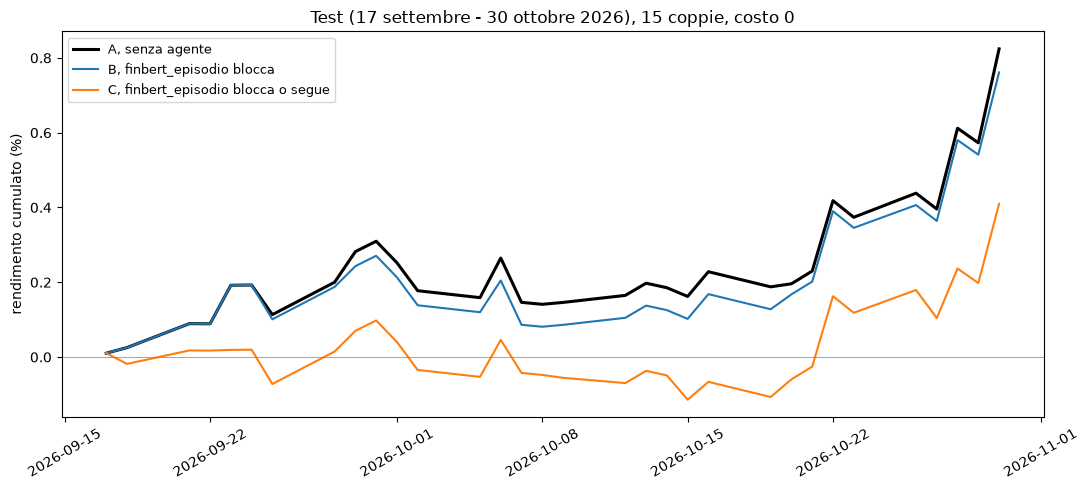

In [12]:
eq = lambda t: daily_pnl(add_costs(t, 0), days).equity * 100   # noqa: E731
fig, ax = plt.subplots(figsize=(11, 5))
for (v, t), color, lw in zip(VERSIONI.items(), ("black", "tab:blue", "tab:orange"), (2.2, 1.5, 1.5)):
    ax.plot(days, eq(t), color=color, lw=lw, label={"A": "A, senza agente", "B": "B, finbert_episodio blocca", "C": "C, finbert_episodio blocca o segue"}[v])
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("rendimento cumulato (%)")
ax.set_title("Test (17 settembre - 30 ottobre 2026), 15 coppie, costo 0")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_TEST / "curve_capitale.png", dpi=120)
plt.show()

## 6. Salvataggio

Tabelle in `Results/test/`, su git.

In [13]:
tables = {"test/confronto_versioni": confronto_test, "test/A_per_costo": per_costo(A), "test/A_per_coppia": by_group(A, "pair", cost_bps=0),
          "test/bloccati_contro_caso": blocchi, "test/notizia_giusta_C": segui, "test/coerenza_con_train": coer}
for p in save_results(tables):
    print(p.relative_to(RESULTS.parent))

Results/test/confronto_versioni.csv
Results/test/A_per_costo.csv
Results/test/A_per_coppia.csv
Results/test/bloccati_contro_caso.csv
Results/test/notizia_giusta_C.csv
Results/test/coerenza_con_train.csv


## 7. Cosa ci dicono i risultati

Numeri delle tabelle qui sopra: test, dal 17 settembre al 30 ottobre 2026, 15 coppie, 500 segnali, costo 0 salvo dove è detto.

**Versione A.** 500 trade con +4,94 punti base lordi ciascuno (train 7,44): +2.472 dollari su 300.000 in 32 giorni (+0,8%). La strategia di base guadagna ancora a costo 0, ma meno che sul train. Il pareggio scende a 1,24 bps per operazione (train 1,86): a 5 bps la A perde 7.528 dollari.
- Guadagnano i trade che rientrano (244 trade, +33 bps); perdono quelli chiusi dopo 90 minuti (227 trade, -23,5 bps).
- Sul test il gap della notte non fa più la differenza: 4,9 bps per gli ingressi nei minuti 15-30 e 5,0 dopo (train 11,4 contro 3,9).
- Le coppie cambiano molto. PYPL-XYZ, la migliore del train (+29,6 bps), sul test è a -3,4; ISRG-SYK passa da -3,2 a +25,7. Gli errori standard per coppia sono grandi.

**Criterio principale (costo 0).** La B guadagna **189 dollari meno della A**, la C **1.242 dollari meno**. Come sul train (B -285, C -651), nessuna delle due batte la A. A costo 5: B -49, C -1.142.

**B: l'agente blocca i trade giusti?** No. Su 500 segnali ne blocca 7. Nella A quei trade avrebbero guadagnato in media +27 bps (mediano +37), contro +4,6 dei trade tenuti. Rientrano nel 43% dei casi contro il 49% dei tenuti (p Fisher 1,00). Il controllo con i blocchi a caso dà p = 0,90: l'agente toglie trade migliori della media, come sul train (p = 0,97).

Le notizie dei blocchi spiegano perché. La regola a parole chiave scatta su notizie che non sono fatti strutturali che allontanano i due prezzi:
- due blocchi su ISRG-SYK vengono da comunicati di studi legali che "indagano" per possibili cause collettive;
- tre vengono da acquisizioni fatte dall'azienda della coppia: Stryker compra ZuriMED, Salesforce compra Braze e Rune Technologies;
- uno da un'acquisizione di Leica Biosystems (gruppo Danaher), uno da un'iniziativa di Bank of America contro le frodi.

Le regole non si cambiano dopo il test: è un limite da dichiarare.

**C: seguire la notizia ha senso?** No. In 21 segnali la C entra nel verso opposto alla A: la notizia ha ragione solo nel **24%** dei casi (train 55%). Quei trade perdono in media 25 bps, mentre la A sugli stessi segnali avrebbe guadagnato 25 bps. In 15 dei 21 l'episodio è nato nella notte.

**Coerenza con il train.** In tutti e quattro i confronti (B e C, costo 0 e 5) la differenza dalla A ha lo stesso segno del train: negativa. Per giorno di borsa la B perde più o meno come sul train (5,9 dollari al giorno contro 4,5), la C molto di più (38,8 contro 10,2).

**In sintesi.** Sul test `finbert_episodio` non migliora la strategia: la B perde 189 dollari rispetto alla A, la C 1.242. Il risultato conferma quello del train. La versione migliore resta la A, senza agente, che però guadagna meno che sul train e perde con costi realistici. Se le differenze sono vere o fortuna lo dice il [Passaggio 7 sul test](07_test_robustezza.ipynb).

**Limiti.**
- 32 giorni, 7 blocchi e 21 trade seguiti: pochi casi, ogni numero ha molta incertezza.
- Nel test ci sono molte più notizie al giorno che nel train: 2.725 in 44 giorni di calendario, contro 2.106 in 108. Probabilmente pesa la stagione dei risultati di ottobre.
- Segnale, variante e soglie sono stati scelti sul train; il test è stato usato una volta sola.
- Le regole in [docs/Test.md](../docs/Test.md) sono state scritte prima del giro ma messe su git dopo: su git non c'è una prova che vengano prima del test. Va dichiarato nel report.